<a href="https://colab.research.google.com/github/adalves-ufabc/2026.Q3-PLN/blob/main/2026_Q3_PLN_AULA_11_Notebook_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processamento de Linguagem Natural [2026-Q3]**
Prof. Alexandre Donizeti Alves

## **API Cohere**
---



**Cohere** é uma empresa de IA especializada em fornecer soluções de PLN. Fundada em 2019 por ex-cientistas do Google, a empresa está sediada em Toronto, Canadá.

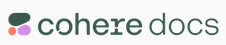

https://docs.cohere.com/

In [ ]:
#@title Instalando a biblioteca da API Cohere
!pip install cohere

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.1/373.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 30.1 MB/s eta 0:00:00


In [ ]:
#@title Versão da API Cohere

import cohere

print(cohere.__version__)

7.3.0


In [ ]:
#@title Definindo a chave da API

from getpass import getpass

COHERE_API_KEY = getpass()

··········


In [ ]:
#@title Teste

import cohere

cliente = cohere.ClientV2(api_key = COHERE_API_KEY)

resposta = cliente.chat(
  model = "command-a-03-2025",
  messages=[
        {
            "role": "user",
            "content": "Qual a capital do Brasil? Responda apenas o nome.",
        }
    ],
  temperature = 0.5
)

print(resposta.message.content[0].text)

Brasília


In [ ]:
#@title Formatando a resposta [Markdown]

from IPython.display import Markdown

Markdown(resposta.message.content[0].text)

Brasília

In [ ]:
#@title Formatando a resposta [JSON]

import json

import json

def formatar_json(resposta):
    dados = json.loads(resposta.json())
    json_formatado = json.dumps(dados, indent=4, ensure_ascii=False)
    linhas = json_formatado.splitlines()
    for linha in linhas:
      print(linha)

In [ ]:
formatar_json(resposta)

{
    "id": "bbdcf02e-8746-4d67-b290-d8b5068b5949",
    "finish_reason": "COMPLETE",
    "message": {
        "role": "assistant",
        "content": [
            {
                "type": "text",
                "text": "Brasília"
            }
        ]
    },
    "usage": {
        "billed_units": {
            "input_tokens": 12.0,
            "output_tokens": 2.0
        },
        "tokens": {
            "input_tokens": 507.0,
            "output_tokens": 5.0
        },
        "cached_tokens": 448.0
    }
}


In [ ]:
resposta.dict()

{'id': 'bbdcf02e-8746-4d67-b290-d8b5068b5949',
 'finish_reason': 'COMPLETE',
 'message': {'role': 'assistant',
  'content': [{'type': 'text', 'text': 'Brasília'}]},
 'usage': {'billed_units': {'input_tokens': 12.0, 'output_tokens': 2.0},
  'tokens': {'input_tokens': 507.0, 'output_tokens': 5.0},
  'cached_tokens': 448.0}}

In [ ]:
#@title Lista de Modelos

import cohere

cliente = cohere.ClientV2(api_key = COHERE_API_KEY)

resposta = cliente.models.list()

resposta

ListModelsResponse(models=[GetModelResponse(name='c4ai-aya-expanse-32b', is_deprecated=None, endpoints=['generate', 'chat'], finetuned=False, context_length=128000, tokenizer_url='https://storage.googleapis.com/cohere-public/tokenizers/c4ai-aya-expanse-32b.json', default_endpoints=[], features=None, sampling_defaults=None), GetModelResponse(name='c4ai-aya-vision-32b', is_deprecated=None, endpoints=['chat'], finetuned=False, context_length=16384, tokenizer_url='https://storage.googleapis.com/cohere-public/tokenizers/c4ai-aya-vision-32b.json', default_endpoints=[], features=['logprobs', 'vision', 'citations'], sampling_defaults=None), GetModelResponse(name='cohere-transcribe-03-2026', is_deprecated=None, endpoints=['transcriptions'], finetuned=False, context_length=32768, tokenizer_url='https://storage.googleapis.com/cohere-public/tokenizers/cohere-transcribe-03-2026.json', default_endpoints=[], features=None, sampling_defaults=None), GetModelResponse(name='command-a-03-2025', is_depreca

In [ ]:
modelos = resposta.models

for modelo in modelos:
  print(modelo.name)

c4ai-aya-expanse-32b
c4ai-aya-vision-32b
cohere-transcribe-03-2026
command-a-03-2025
command-a-plus-05-2026
command-a-reasoning-08-2025
command-a-translate-08-2025
command-a-vision-07-2025
command-r-08-2024
command-r-plus-08-2024
command-r7b-12-2024
command-r7b-arabic-02-2025
embed-english-light-v3.0
embed-english-light-v3.0-image
embed-english-v3.0
embed-english-v3.0-image
embed-multilingual-light-v3.0
embed-multilingual-light-v3.0-image
embed-multilingual-v3.0
embed-multilingual-v3.0-image


In [ ]:
len(modelos)

20

**Conversas de Múltiplas Interações (*Multi-turn*)**

Uma única solicitação de chat pode englobar várias etapas de uma conversa, em que cada mensagem na lista de mensagens aparece na ordem em que foi enviada. O envio de múltiplas mensagens pode fornecer ao modelo o contexto necessário para gerar uma resposta.

In [ ]:
import cohere

cliente = cohere.ClientV2(api_key = COHERE_API_KEY)

system_message = "Você responde de forma concisa, em cerca de 5 palavras ou menos."

resposta = cliente.chat(
    model="command-a-03-2025",
    messages=[
        {"role": "system", "content": system_message},
        {
            "role": "user",
            "content": "Escreva um título para uma postagem de blog sobre design de API. Exiba apenas o texto do título.",
        },
        {"role": "assistant", "content": "Projetando APIs perfeitas"},
        {
            "role": "user",
            "content": "Mais um sobre IA Generativa.",
        },
    ],
)

print(resposta.message.content[0].text)

IA Generativa: Criando o Futuro


In [ ]:
from IPython.display import Markdown

Markdown(resposta.message.content[0].text)

IA Generativa: Criando o Futuro

**Saída Estruturada**

In [ ]:
import cohere

cliente = cohere.ClientV2(api_key = COHERE_API_KEY)

resposta = cliente.chat(
    model="command-a-03-2025",
    messages=[
        {
            "role": "user",
            "content": "Gere um JSON descrevendo uma pessoa, com os campos 'nome' e 'idade'.'",
        }
    ],
    response_format={"type": "json_object"},
)

print(resposta.message.content[0].text)

{
  "nome": "João Silva",
  "idade": 30
}


In [ ]:
import cohere

cliente = cohere.ClientV2(api_key = COHERE_API_KEY, log_warning_experimental_features=False)

resposta = cliente.chat(
    model="command-a-03-2025",
    messages=[
        {
            "role": "user",
            "content": "Gere um JSON descrevendo um livro, com os campos 'título', 'autor' e 'ano_de_publicação'.'",
        }
    ],
    response_format={
        "type": "json_object",
        "schema": {
            "type": "object",
            "properties": {
                "title": {"type": "string"},
                "author": {"type": "string"},
                "publication_year": {"type": "integer"},
            },
            "required": ["title", "author", "publication_year"],
        },
    },
)

print(resposta.message.content[0].text)

{"title": "1984", "author": "George Orwell", "publication_year": 1949}


**Imagens**

In [ ]:
import cohere
from IPython.display import display, Markdown, Image

cliente = cohere.ClientV2(api_key=COHERE_API_KEY)

url_imagem = "https://upload.wikimedia.org/wikipedia/commons/a/a8/Tour_Eiffel_Wikimedia_Commons.jpg"

imagem = {
    "type": "image_url",
    "image_url": {
        "url": url_imagem
    }
}

prompt = """
Analise a imagem e responda em português:
1. O que aparece na imagem?
2. Quais são as principais características do local?
3. Que informações adicionais podem ser inferidas visualmente?
Organize a resposta em tópicos Markdown.
"""

resposta = cliente.chat(
    model="command-a-vision-07-2025",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                imagem
            ]
        }
    ]
)

In [ ]:
# Exibir a imagem utilizada no exemplo
display(Image(url=url_imagem, width=400))

In [ ]:
display(Markdown(resposta.message.content[0].text))

1. **O que aparece na imagem?**
   - A imagem apresenta a Torre Eiffel, um dos monumentos mais famosos do mundo, localizado em Paris, França. A torre é vista de frente, destacando sua estrutura de ferro e seus três níveis. O céu está claro e azul, proporcionando um fundo perfeito para a torre.

2. **Principais características do local:**
   - **Estrutura da Torre Eiffel:**
     - A torre possui uma estrutura de ferro com um design de treliça, que é tanto forte quanto leve.
     - São visíveis os três níveis da torre, com o primeiro e segundo níveis possuindo plataformas para visitantes.
   - **Área circundante:**
     - A base da torre é cercada por um amplo espaço verde, que parece ser o Champ de Mars, um grande parque público.
     - Há árvores alinhadas nas laterais do parque, proporcionando uma moldura natural para a torre.
     - No fundo, além da torre, são visíveis alguns edifícios, provavelmente parte da paisagem urbana de Paris.

3. **Informações adicionais que podem ser inferidas visualmente:**
   - **Clima e tempo:**
     - O céu está claro e azul, indicando um dia ensolarado e provavelmente agradável.
   - **Turismo:**
     - A presença de pessoas no parque sugere que este é um local popular para turistas e visitantes.
   - **Manutenção:**
     - A torre parece estar em bom estado de conservação, com sua estrutura e pintura aparentemente bem-mantidas.

Esta análise fornece uma visão abrangente da imagem, destacando as principais características da Torre Eiffel e de seu entorno, além de inferir informações adicionais sobre o clima, turismo e manutenção do monumento.

A API de Chat permite que os usuários controlem o nível de "detalhe" da imagem enviada ao modelo, que pode ser `low`, `high` ou `auto` (valor default).

Um nível de detalhe menor ajuda a reduzir a quantidade total de tokens (e, portanto, o preço e a latência), mas pode resultar em um desempenho inferior. Recomendamos testar os dois níveis de detalhe para verificar se o desempenho é suficiente no nível `low`.

A propriedade de detalhe é especificada para cada imagem. Veja como fica:

In [ ]:
resposta = cliente.chat(
  model="command-a-vision-07-2025",
  messages=[
	{ "role": "user", "content": [
            {"type": "text",
              "text": "O que tem nessa imagem?"
              },
            {"type": "image_url",
            "image_url": {
              "url": "https://cohere.com/favicon-32x32.png",
              "detail": "high"
          }
        },
      ]
    }
  ]
)


In [ ]:
from IPython.display import Markdown

Markdown(resposta.message.content[0].text)

A imagem contém três formas geométricas simples. No topo, há um grande círculo verde escuro. Abaixo e ligeiramente à esquerda do círculo, há um menor quadrado laranja. À direita do quadrado laranja, há um círculo menor roxo. As formas estão dispostas em um triângulo desigual, com o círculo verde no vértice superior e os quadrado laranja e círculo roxo nos vértices inferiores.

**Referências**:

> https://docs.cohere.com/docs/the-cohere-platform

> https://docs.cohere.com/docs/chat-api

> https://docs.cohere.com/docs/structured-outputs

> https://docs.cohere.com/docs/image-inputs

